# 00_environment_check
Date: 11/10/2026
Purpose: Set up Colab, check the GPU, install and test all tools.
Data version used: none yet

In [ ]:
SEED = 42
BASE = '/content/drive/MyDrive/kpneu_project'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
folders = ['data/raw','data/clean','data/splits','models/qsar','models/clm',
           'generated','docking/receptors','docking/ligands','docking/results',
           'notebooks','reports']
for f in folders:
    os.makedirs(f'{BASE}/{f}', exist_ok=True)
print('Folders ready at', BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folders ready at /content/drive/MyDrive/kpneu_project


In [ ]:
!nvidia-smi

Sun Oct 11 14:13:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!apt-get -qq install -y openbabel swig libboost-all-dev
!pip install -q rdkit selfies meeko gemmi vina

In [ ]:
import importlib, sys
print('Python', sys.version.split()[0])
for name in ['rdkit','torch','sklearn','pandas','matplotlib','selfies','vina','meeko']:
    try:
        m = importlib.import_module(name)
        print('OK  ', name, getattr(m, '__version__', ''))
    except Exception as e:
        print('FAIL', name, '->', e)

import torch
print('GPU available:', torch.cuda.is_available())

Python 3.13.15
OK   rdkit 2026.09.1
OK   torch 2.11.0+cu130
OK   sklearn 1.6.1
OK   pandas 2.2.3
OK   matplotlib 3.10.0
OK   selfies 2.1.1
OK   vina 1.2.7
OK   meeko 0.8.0
GPU available: True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Molecular weight: 180.16
Fingerprint bits on: 24


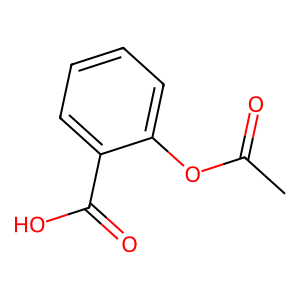

In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, rdFingerprintGenerator

mol = Chem.MolFromSmiles('CC(=O)Oc1ccccc1C(=O)O')   # aspirin
print('Molecular weight:', round(Descriptors.MolWt(mol), 2))   # about 180.16

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
print('Fingerprint bits on:', gen.GetFingerprint(mol).GetNumOnBits())
Draw.MolToImage(mol)

In [ ]:
from vina import Vina
v = Vina(sf_name='vina')
print('Vina works')

Vina works


In [ ]:
!obabel -V

Open Babel 3.1.1 -- Mar 31 2024 -- 06:39:03


In [ ]:
!git clone --depth 1 https://github.com/MolecularAI/REINVENT4.git {BASE}/REINVENT4

fatal: destination path '/content/drive/MyDrive/kpneu_project/REINVENT4' already exists and is not an empty directory.


CLM route: REINVENT 4 with a pretrained prior. Fallback: SMILES-LSTM, or SELFIES version if molecule validity is poor.

In [ ]:
!pip freeze > {BASE}/reports/env_packages_day1.txt
!nvidia-smi > {BASE}/reports/gpu_day1.txt
print('Saved environment record to Drive')

Saved environment record to Drive
